In [32]:
"""
code to
(1) clean up bad data based on observation type and filters,
(2) combine all years together (bottle or ctd),
(3) plot all cast monthly,
(4) save data into two sets: bottle and ctd

"""
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt
from lo_tools import plotting_functions as pfun
from lo_tools import Lfun

In [33]:
Ldir = Lfun.Lstart()
# where to read data in
in_dir = Ldir['parent'] / 'LPM_output' / 'obsmod'
# where to put output figures
out_dir = Ldir['LOo'] / 'LO_bias_corr' / 'plots' / fod / 'cast'
Lfun.make_dir(out_dir)
# where to save data
data_dir = Ldir['LOo'] / 'LO_bias_corr' / 'data' / fod
Lfun.make_dir(data_dir)

In [34]:
source = 'all' # source can be
# source = 'GroundfishTrawl'
# data choices
otype = 'bottle'
# otype = 'ctd'

if otype == 'bottle':
    source_list = ['LineP', 'nceiCoastal', 'dfo1', 'nceiSalish', 'WOD', 'nceiPNW','HABRISE','benthic_OSU']
    # source_list = ['nceiCoastal']
else:
    source_list = ['LineP', 'NHL', 'OCNMS','Hake','IPHC', 'GroundfishTrawl']

# ========= SET FILTERS =============================================

fil_dict = dict()  # dict to hold filter choices

# Set mask_salish to True to ignore stations in the Salish Sea
fil_dict['mask_salish'] = True
fil_dict['clean_up'] = True

if fil_dict['clean_up']:
    fod = 'processed'
else:
    fod = 'raw'
if 'IPHC' in source_list:
    fil_dict['mask_bad_cids_IPHC'] =  True   # need to remove some bad casts
    bad_cids_iphc = {
        (2009, 606), (2009, 599), (2009, 602), (2009, 598),
        (2009, 600), (2009, 624), (2009, 622), (2009, 627),
        (2009, 616), (2009, 610), (2009, 639), (2009, 635),
        (2010, 559), (2010, 560), (2010, 564), (2010, 566),
        (2010, 575), (2010, 573), (2010, 617), (2010, 614),
        (2011, 703), (2011, 706), (2011, 707), (2011, 719),
        (2011, 727), (2011, 747), (2011, 748), (2011, 759),
        (2011, 768), (2011, 770), (2011, 803), (2011, 792),
        (2011, 804), (2011, 807), (2011, 803), (2011, 824),
        (2011, 826), (2011, 829), (2011, 830), (2011, 824),
        (2012, 570), (2012, 572), (2012, 573), (2012, 569),
        (2012, 650), (2014, 450), (2014, 460), (2014, 463),
        (2014, 495), (2014, 496), (2014, 499), (2014, 563),
        (2014, 564), (2014, 567), (2014, 568), (2014, 579),
        (2015, 612), (2015, 628), (2015, 630), (2015, 638),
        (2015, 643), (2015, 659), (2015, 661), (2015, 663),
        (2015, 723), (2016, 464), (2016, 463), (2016, 461),
        (2016, 474), (2016, 475), (2016, 493), (2016, 536),
        (2016, 544), (2016, 529), (2016, 481), (2016, 474),
        (2016, 487), (2016, 489), (2016, 499), (2016, 511),
        (2016, 513), (2016, 514), (2016, 530), (2016, 529),
        (2017, 530), (2017, 511), (2017, 513), (2017, 514),
        (2017, 517), (2017, 521), (2017, 487), (2017, 492),
        (2017, 474), (2017, 485),
        (2018, 536), (2018, 543), (2018, 615), (2018, 613),
        (2022, 94), (2022, 142)
    }
    # too many, I think it's better to remove upper 15 meter
else:
    fil_dict['mask_bad_cids_IPHC'] =  False

if ('HABRISE' in source_list) and (otype == 'ctd'):
    fil_dict['mask_bad_cids_HAB'] =  True   # need to remove some bad casts
    bad_cids_HAB = {

        (2003, 517), (2003, 531), (2003, 529), (2003, 540),
        (2003, 546), (2003, 547), (2003, 548), (2003, 560),
        (2003, 581), (2003, 582), (2003, 584), (2003, 580),
        (2003, 578), (2003, 575), (2003, 618), (2003, 619),
        (2003, 620), (2003, 621), (2003, 651),
        (2004, 564), (2004, 569), (2004, 574), (2004, 583),
        (2004, 585), (2004, 587), (2004, 591), (2004, 592),
        (2004, 599), (2004, 602), (2004, 607), (2004, 621),
        (2004, 616), (2004, 637), (2004, 638), (2004, 628),
        (2004, 661), (2004, 662), (2004, 670), (2004, 678),
        (2004, 688), (2004, 689), (2004, 694), (2004, 696),
        (2004, 697), (2004, 709), (2004, 726), (2004, 727),
        (2005, 1080),
    }


else:
    fil_dict['mask_bad_cids_HAB'] =  False


fil_dict['shallow_ctd'] =  True

if 'Hake' in source_list:
    fil_dict['mask_bad_cids_HAKE'] =  True
    bad_cids_HAKE = {
        (2015, 524), (2012, 493), (2012, 504), (2012, 497),
        (2012, 505), (2011, 681), (2011, 683), (2011,660 ),
        (2011, 661), (2011, 671), (2011, 656), (2011, 655),
        (2011, 618), (2011, 585), (2011, 590), (2011, 579),
        (2011, 567), (2011, 662), (2011, 604),
    }
else:
    fil_dict['mask_bad_cids_HAKE'] =  False

if ('OCNMS' in source_list) and (otype == 'ctd'):
    fil_dict['mask_bad_cids_OCNMS'] =  True
    bad_cids_OCNMS = {

        (2005, 388), (2005, 276), (2004, 539),
        (2007, 335), (2007, 340), (2007, 347), (2007, 344),
        (2007, 340), (2008, 596), (2008, ), (2008, 599),
        (2009, 560), (2009, 561), (2009, 564), (2009, 568),
        (2009, 572), (2009, 575), (2009, 578), (2011, 530),
        (2011, 535), (2011, 539), (2011, 542), (2011, 543),
        (2011, 558), (2012, 413), (2012, 420), (2012, 435),
        (2012, 439), (2012, 445), (2012, 461), (2013, 224),
        (2013, 243), (2013, 255), (2013, 249), (2014, 412),
        (2014, 424), (2014, 439), (2015, 489), (2015, 501),
        (2016, 366), (2016, 376), (2016, 379), (2016, 402),
        (2017, 391), (2017, 411), (2018, 389), (2019, 385),
        (2019, 395), (2019, 400), (2019, 405), (2019, 421),
        (2019, 426), (2020, 300), (2020, 304), (2020, 306),
        (2020, 307), (2020, 314), (2020, 315), (2021, 212),
        (2021, 222), (2019, 392), (2019, 402),

    }
else:
    fil_dict['mask_bad_cids_OCNMS'] =  False

if source == 'all' and otype == 'ctd':
    if 'Hake' in source_list:
        yr_list = [str(year) for year in range(1998, 2023)] # added Hake+IPHC
    else:
        yr_list = [str(year) for year in range(1998, 2022)]
    # yr_list = [str(year) for year in range(2007, 2022)]  # good DO data starts at 1998 for NHL, 2001 for DFO1
    print(yr_list)
elif source == 'all' and otype == 'bottle':
    # yr_list = [str(year) for year in range(1993, 2022)]
    yr_list = [str(year) for year in range(1993, 2022)]
    print(yr_list)
elif source == 'HABRISE' and otype == 'ctd':
    yr_list = [str(year) for year in range(2003, 2007)]
elif source == 'IPHC' and otype == 'ctd':
    yr_list = [str(year) for year in list(range(2009, 2019)) + [2022]]
else:
    yr_list = [str(yr) for yr in [2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2022]]
    print(yr_list)

out_fn = data_dir / ('combined_' + otype + '_' + source+ '_' + yr_list[0] + '-' + yr_list[-1] + '.p')

['1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021']


In [35]:
# model run version
gtx = 'cas2k_v4_lo2b'

# dicts to help with plotting
lim_dict = {'SA':(14,36),'CT':(0,20),'DO (uM)':(0,500),
            'NO3 (uM)':(0,50),'NH4 (uM)':(0,10),'DIN (uM)':(0,50),
            'DIC (uM)':(1500,2500),'TA (uM)':(1500,2500),'Chl (mg m-3)':(0,20),
            'dDO_dz':(-5, 20),'dSA_dz':(-0.2, 0.2),'dCT_dz':(-0.5, 1)
            }
c_list = ['r','b','y','c']
c_dict = {'obs':'k',
          gtx:'r',}

1993
1994
1995
1996
1997
1998
1999
2000
2001
2002
2003
2004
2005
2006
2007
2008
2009
2010
2011
2012
2013
2014
2015
2016
2017
2018
2019
2020
2021


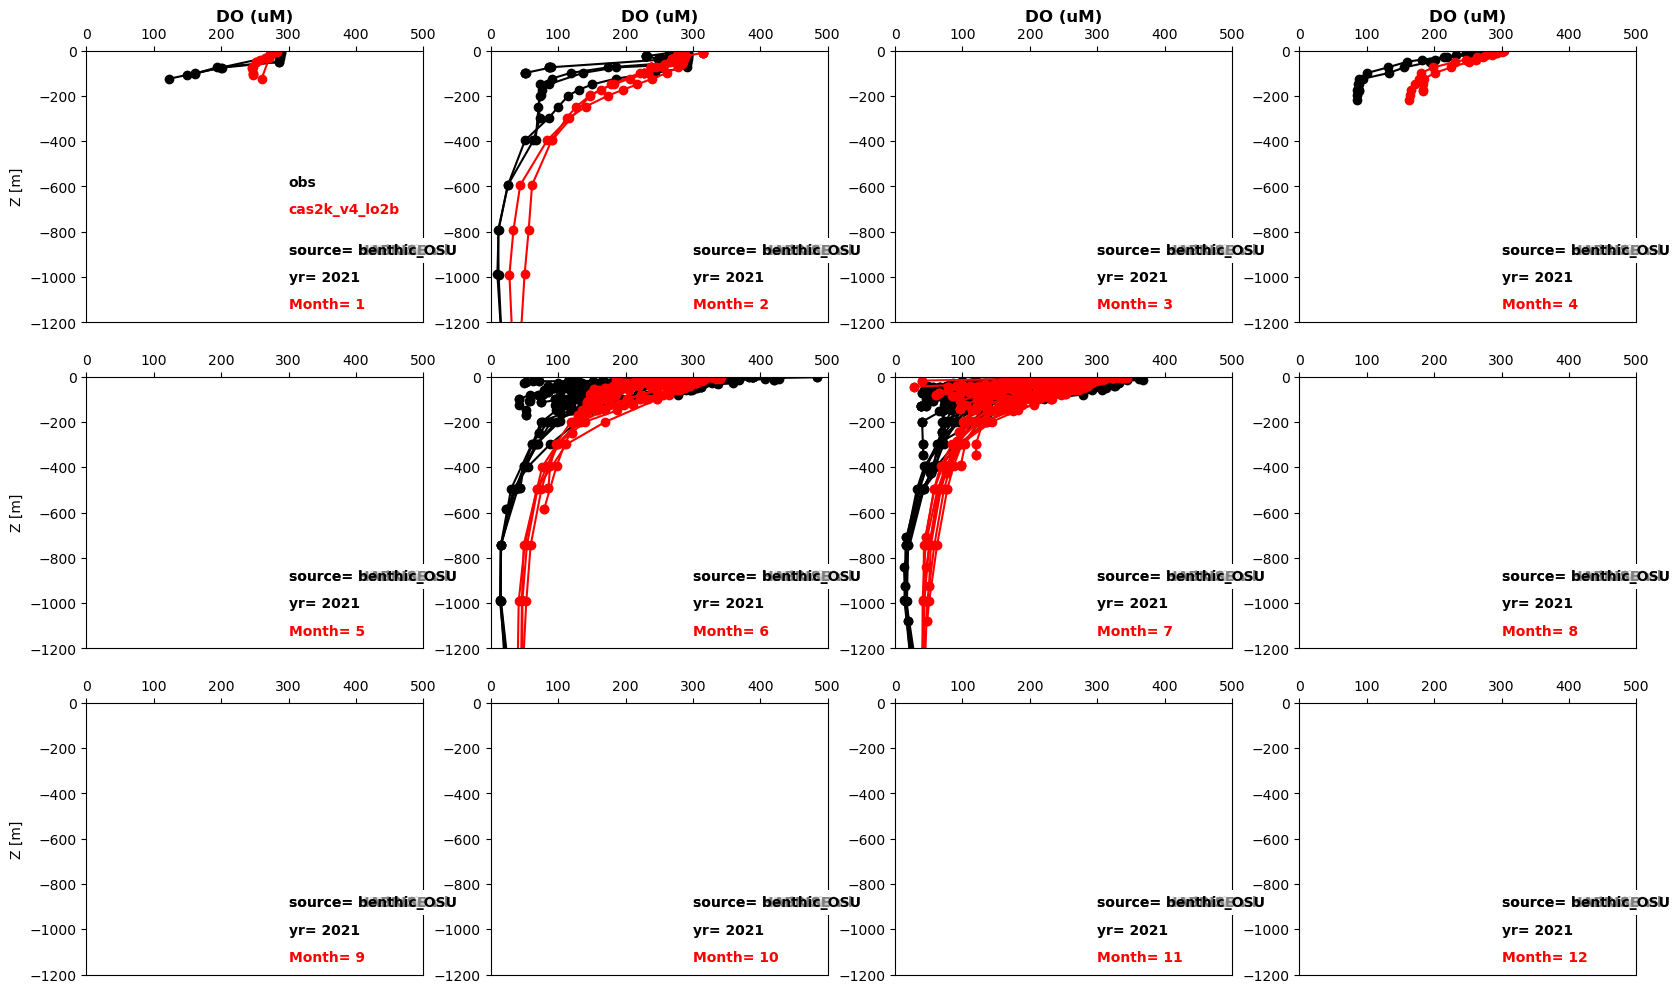

In [36]:
"""
clean up bad data based on observation type and filters,
combine all years together (bottle or ctd), then plot all cast monthly,
and save data into two sets: bottle and ctd
"""

df_dict0 = {'obs': pd.DataFrame(),
            gtx: pd.DataFrame()
            }
# check the folder
for year in yr_list:
    print(year)
    # ff_str = otype + '_' + yr_list[0] +'-'+ yr_list[-1] + '_' + gtx # a string for the output .png file name
    ff_str = otype + '_' + year + '_' + gtx # a string for the output .png file name
    # specify input (created by process_multi_bottle.py)
    # in_fn = in_dir / ('multi_' + otype + '_' + str(year) + '.p')
    # in_fn = in_dir / ('combined_' + otype + '_' + 'all'+ '_' +str(year) + '_' + str(year) + '.p')
    in_fn = in_dir / ('combined_' + otype + '_'  +str(year) + '_' + str(gtx) + '.p')
    df0_dict = pickle.load(open(in_fn, 'rb'))
    # ======== APPLY FILTERS ==================================
    if fil_dict['clean_up']:
        b = df0_dict[gtx].copy()
        mask0 = pd.isna(b['CT']) # this masks off out of bound, no extracted data
        df0_dict['obs'] = df0_dict['obs'].loc[~mask0, :]
        df0_dict[gtx] = b.loc[~mask0, :]
        a = df0_dict['obs'].copy()
        # print(a['time'].dtype)
        # if year ==2009:
        #     a['time'] = pd.to_datetime(a['time'])
        if otype == 'bottle':
            mask1 =  pd.isna(a['CT'])| pd.isna(a['SA'])| pd.isna(a['DO (uM)']) |(a['DO (uM)'] < 0) | (a['DO (uM)'] > 650) | (a['NO3 (uM)'] > 55)
            mask2 = (a['source']=='dfo1') &(a['CT'] < 1.47)
            mask3 = (a['source']=='dfo1') & (a['z'] > -10) & (a['DO (uM)'] < 100)
            mask4 = (a['source']=='dfo1') & (a['z'] > -200) & (a['DO (uM)'] <11)
            mask5 = (a['source']=='dfo1') & (a['time'].dt.year == 1997) & (a['time'].dt.month == 4)
            mask6 = ((a['source']=='dfo1') & (a['time'].dt.year == 1998) & (a['time'].dt.month == 5))
            mask7 = ((a['source']=='dfo1') & (a['time'].dt.year == 1998) & (a['time'].dt.month == 7))
            mask8 = ((a['source']=='dfo1') & (a['time'].dt.year == 2019) & (a['time'].dt.month == 9)  &  (a['time'].dt.day == 3))
            mask9 = ((a['source']=='dfo1') & (a['time'].dt.year == 2016) & (a['time'].dt.month == 8)  &  (a['time'].dt.day == 5))
            mask10 = ((a['source']=='dfo1') & (a['time'].dt.year == 2016) & (a['time'].dt.month == 8)  &  (a['time'].dt.day == 6))
            mask11 = ((a['source']=='WOD') & (a['time'].dt.year == 1994) & (a['z'] < -250) & (a['DO (uM)'] >160))
            mask12 = ((a['source']=='WOD') & (a['time'].dt.year == 1994) & (a['time'].dt.month == 4)  &  (a['time'].dt.day == 1))
            mask13 = ((a['source']=='nceiPNW') & (a['time'].dt.year == 2016) & (a['time'].dt.month == 6)  &  (a['time'].dt.day == 7))
            mask14 = ((a['source']=='nceiCoastal') & (a['time'].dt.year == 2017) & (a['time'].dt.month == 9)  &  (a['time'].dt.day == 24))
            ## for NO3
            mask15 = (a['source']=='dfo1') & (a['z'] < -190) & (a['NO3 (uM)'] <23.5)
            mask16 = (a['source']=='dfo1') & (a['z'] < -400) & (a['NO3 (uM)'] <35)
            mask17 = (a['source']=='dfo1') & (a['z'] > -400) & (a['z'] < -350) & (a['NO3 (uM)'] <30)
            mask18 = (a['source']=='nceiSalish') & (a['z'] < -185) & (a['NO3 (uM)'] <25)
            mask19 = ((a['source']=='nceiCoastal') & (a['time'].dt.year == 2013) & (a['z'] < -120) & (a['NO3 (uM)'] <12))
            mask20 = ((a['source']=='nceiCoastal') & (a['time'].dt.year == 2017) & (a['z'] < -490) & (a['NO3 (uM)'] <35))
            mask21 = ((a['source']=='nceiCoastal') & (a['time'].dt.year == 2021) & (a['z'] < -450) & (a['NO3 (uM)'] <34))
            mask22 = (a['source']=='dfo1')  & (a['NO3 (uM)'] >30) & (a['DO (uM)'] >220)
            mask23 = (a['NO3 (uM)'] <1) & (a['DO (uM)'] <210)
            mask24 = (a['source']=='dfo1')  & (a['NO3 (uM)'] <20) &  (a['NO3 (uM)'] >10) & (a['DO (uM)'] >350)
            mask25 = (a['NO3 (uM)'] <20) &  (a['NO3 (uM)'] >0) & (a['DO (uM)'] <150)

            mask = ((~mask1) & (~mask2) & (~mask3) & (~mask4) & (~mask5) & (~mask6) & (~mask7) & (~mask8) & (~mask9) & (~mask10)&
                    (~mask11) & (~mask12) & (~mask13) & (~mask14)& (~mask15)& (~mask16)& (~mask17)& (~mask18)& (~mask19)& (~mask20)& (~mask21)& (~mask22)& (~mask23)& (~mask24)& (~mask25))
        elif otype == 'ctd':
            mask1 = pd.isna(a['CT'])| pd.isna(a['SA'])| pd.isna(a['DO (uM)']) | (a['DO (uM)'] < 0) | (a['DO (uM)'] > 650)
            mask2 = (a['source']=='dfo1') &(a['CT'] < 1.47)
            mask3 = (a['source']=='dfo1') & (a['z'] > -10) & (a['DO (uM)'] < 100)
            mask4 = (a['source']=='dfo1') & (a['z'] > -200) & (a['DO (uM)'] <11)
            mask5 = (a['source']=='LineP') & (a['z'] < -500) & (a['DO (uM)'] >150)
            mask6= (a['source']=='LineP') & (a['time'].dt.year == 2011) & (a['time'].dt.month == 10)& (a['z'] > -80) & (a['z'] < -60) & (a['DO (uM)'] >340)
            mask7= (a['source']=='dfo1') & (a['time'].dt.year == 2018) & (a['time'].dt.month == 7) & (a['z'] > -80) & (a['z'] < -60) & (a['DO (uM)'] >300)
            mask8 = (a['source']=='dfo1') & (a['time'].dt.year == 1997) & (a['time'].dt.month == 4)
            mask9 = ((a['source']=='dfo1') & (a['time'].dt.year == 1998) & (a['time'].dt.month == 5))
            mask10 = ((a['source']=='dfo1') & (a['time'].dt.year == 1998) & (a['time'].dt.month == 7))
            mask11 = ((a['source']=='dfo1') & (a['time'].dt.year == 2019) & (a['time'].dt.month == 9)  &  (a['time'].dt.day == 3))
            mask12 = ((a['source']=='dfo1') & (a['time'].dt.year == 2016) & (a['time'].dt.month == 8)  &  (a['time'].dt.day == 5))
            mask13 = ((a['source']=='dfo1') & (a['time'].dt.year == 2016) & (a['time'].dt.month == 8)  &  (a['time'].dt.day == 6))
            mask14= (a['source']=='dfo1') & (a['time'].dt.year == 2011) & (a['time'].dt.month == 2) & (a['z'] > -80) & (a['z'] < -60) & (a['DO (uM)'] >330)
            mask15= (a['source']=='dfo1') & (a['time'].dt.year == 2011) & (a['time'].dt.month == 2) & (a['z'] < -500) & (a['DO (uM)'] >100)
            mask16 = (a['source']=='NHL')  & (a['CT'] >10) & (a['DO (uM)'] <140)
            mask17 = (a['source']=='NHL')  & (a['CT'] <3) & (a['DO (uM)'] >110)
            mask18 = (a['source']=='NHL')  & (a['CT'] <3) & (a['SA'] <34.2)
            mask19 = (a['source']=='NHL')  & (a['CT'] <3) & (a['SA'] <34.2)
            mask20 = (a['source']=='NHL')  & (a['DO (uM)'] <200) & (a['SA'] <32)
            mask21 = (a['source']=='NHL')  & (a['CT'] <15) & (a['SA'] >35)
            mask22 = (a['source']=='NHL')  & (a['DO (uM)'] >100) & (a['SA'] >34.25)
            mask23 = (a['source']=='NHL')  & (a['CT'] >7.4) & (a['SA'] >34.25)
            mask24 = (a['source']=='NHL')  & (a['CT'] >10) & (a['SA'] <34.25)& (a['SA'] >34)
            mask25 = (a['source']=='NHL')  & (a['CT'] >15) & (a['SA'] <33.4)& (a['SA'] >33.2)
            mask26 = (a['source']=='NHL')  & (a['DO (uM)'] <105) & (a['SA'] <33.5)& (a['SA'] >33)
            mask27 = (a['source']=='NHL')  & (a['DO (uM)'] <150) & (a['SA'] <33)& (a['SA'] >32)

            mask = (~mask1) & (~mask2) & (~mask3) & (~mask4) & (~mask5) & (~mask6) & (~mask7)& (~mask8) & (~mask9) & (~mask10)& (~mask11) & (~mask12) & (~mask13) & (~mask14)& (~mask15)& (~mask16)& (~mask17) & (~mask18)& (~mask19)& (~mask20)& (~mask21)& (~mask22)&(~mask23)&(~mask24)&(~mask25)&(~mask26)&(~mask27)




        df0_dict['obs'] = a.loc[mask, :]
        df0_dict[gtx] = df0_dict[gtx].loc[mask, :]  # Apply mask to model as well

        # mask out Salish Fields
    if fil_dict['mask_salish']:
        for gtxo in df0_dict.keys():
            a = df0_dict[gtxo].copy()
            mask1 = (a.lat >= 46) & (a.lat < 49) & (a.lon > -124)
            mask2 = (a.lat >= 49) & (a.lat < 51) & (a.lon > -125)
            mask3 = (a.lat >= 49.5) & (a.lat < 52) & (a.lon > -126)
            mask4 = (a.lat >= 50) & (a.lat < 52) & (a.lon > -128.5)
            mask5 = (a.lat >= 48.5) & (a.lat < 49.5) & (a.lon > -125.5)
            mask6 = (a.lat >= 49) & (a.lat < 51) & (a.lon > -126.5)
            mask7 = (a.lat >= 51) & (a.lat < 52) & (a.lon > -128) & (a.lon < -126.5)
            a = a.loc[(~mask1) & (~mask2) & (~mask3) & (~mask4) & (~mask5) & (~mask6) & (~mask7), :]
            df0_dict[gtxo] = a

    df_dict = df0_dict.copy()

    """save_data"""
    #
    df_dict0['obs'] = pd.concat([df_dict0['obs'], df0_dict['obs']], ignore_index=True)
    df_dict0[gtx]= pd.concat([df_dict0[gtx], df0_dict[gtx]], ignore_index=True)

    columns = ['NH4 (uM)', 'NO2 (uM)']
    df_dict0['obs'].drop(columns=columns, errors='ignore')
    df_dict0[gtx].drop(columns=columns, errors='ignore')

    # plotting
    plt.close('all')

    fig, axes = plt.subplots(3, 4, figsize=(20, 12), sharex=True, sharey=False)
    axes = axes.flatten()

    ax_dict = {}
    zbot = 0
    vn = 'DO (uM)'
    # vn = 'NO3 (uM)'
    # vn = 'CT'
    # vn = 'SA'

    jj = 0
    for month in range(1, 13):  # Loop through each month
        ax = axes[month - 1]  # Assign subplot by month index
        ax_dict[month] = ax
        ax.xaxis.set_label_position('top')
        ax.xaxis.tick_top()
        ax.xaxis.set_tick_params(labeltop=True, labelbottom=False)
        ax.text(.6,.05, f'Month= {month}', color=c_dict[gtx],transform=ax.transAxes,
                 fontweight='bold',bbox=pfun.bbox)
        ax.text(.6,.15, f'yr= {year}', color= 'k',transform=ax.transAxes,
                fontweight='bold',bbox=pfun.bbox)


        for gtx in df_dict.keys():
            month_mask = df_dict[gtx]['time'].dt.month == month
            df0_month = df_dict[gtx][month_mask]
            if month == 1:

                ax.text(.6,0.5-jj,gtx, color=c_dict[gtx],transform=ax.transAxes,
                        fontweight='bold',bbox=pfun.bbox)
                jj += 0.1
            for source in source_list:
                df_month = df0_month[df0_month['source'] == source]
                ax.text(.6,.25, f'source= {source}', color= 'k',transform=ax.transAxes,
                        fontweight='bold',bbox=pfun.bbox)

                if not df_month.empty:
                    for cid in df_month.cid.unique():
                        df_cid = df_month[df_month.cid == cid]
                        x = df_cid[vn].to_numpy()
                        y = df_cid['z'].to_numpy()
                        zbot = np.nanmin((zbot, np.min(y)))

                        if otype == 'bottle':
                            ax.plot(x, y, '-o', c=c_dict[gtx])
                        elif otype == 'ctd':
                            ax.plot(x, y, '.', c=c_dict[gtx])

        ax.set_xlim(lim_dict[vn])
        # ax.set_ylim(zbot, 0)
        if month in [1, 5, 9]:  # First column
            ax.set_ylabel('Z [m]')
        if month in [1, 2, 3, 4]:  # First row
            ax.set_xlabel(vn, fontsize=12, fontweight='bold')

    # # Set consistent y-limits for all subplots
    if source == 'OCNMS':
        for ax in ax_dict.values():
            ax.set_ylim(-120, 0)
    elif source == 'NHL'  or source == 'nceiSalish':
            for ax in ax_dict.values():
                ax.set_ylim(-500, 0)
    elif source == 'nceiCoastal':
        for ax in ax_dict.values():
            ax.set_ylim(-1200, 0)
    else:
        for ax in ax_dict.values():
            ax.set_ylim(-1200, 0)
    ff_str += '_' + source
    # fig.tight_layout()
    plt.savefig(out_dir / (ff_str +'_' + vn + '.png'),bbox_inches='tight')
    # plt.show()
    if year == 1993:
        plt.show()
    # plt.close(fig)

if otype == 'ctd':
    if fil_dict['mask_bad_cids_IPHC']:
        print('Removing selected IPHC cids:')
        print('Removing IPHC samples in the upper 10 m.')

        for gtx in df_dict0:
            a = df_dict0[gtx].copy()
            year_cid = list(zip(a['time'].dt.year, a['cid']))

            remove_bad_casts = (
                a['source'].eq('IPHC')
                & pd.Series(year_cid, index=a.index).isin(bad_cids_iphc)
            )

            """ remove upper 10m """
            remove_upper_10m = (
                a['source'].eq('IPHC')
                & a['z'].ge(-10)
            )
            # This dataset, has many many surface odd DO
            remove_mask = remove_bad_casts | remove_upper_10m

            df_dict0[gtx] = a.loc[~remove_mask].copy()

    if fil_dict['mask_bad_cids_HAB']:
        print('Removing selected HABRISE cids:', bad_cids_HAB)

        for gtx in df_dict0:
            a = df_dict0[gtx].copy()
            year_cid = list(zip(a['time'].dt.year, a['cid']))
            remove_mask = (
                a['source'].eq('HABRISE')
                & pd.Series(year_cid, index=a.index).isin(bad_cids_HAB)
            )
            df_dict0[gtx] = a.loc[~remove_mask].copy()

    if fil_dict['mask_bad_cids_HAKE']:
        print('Removing selected HAKE cids:', bad_cids_HAKE)
        print('Removing HAKE samples in the upper 15 m.')
        for gtx in df_dict0:
            a = df_dict0[gtx].copy()
            year_cid = list(zip(a['time'].dt.year, a['cid']))
            remove_bad_casts = (
                a['source'].eq('Hake')
                & pd.Series(year_cid, index=a.index).isin(bad_cids_HAKE)
            )
            remove_upper_10m = (
                a['source'].eq('Hake')
                & a['z'].ge(-15)
            )
            remove_mask = remove_bad_casts | remove_upper_10m
            df_dict0[gtx] = a.loc[~remove_mask].copy()

    if fil_dict['mask_bad_cids_OCNMS']:
        print('Removing selected OCNMS cids:', bad_cids_OCNMS)
        print('Removing OCNMS samples in the upper 5 m.')
        for gtx in df_dict0:
            a = df_dict0[gtx].copy()
            year_cid = list(zip(a['time'].dt.year, a['cid']))
            remove_bad_casts = (
                a['source'].eq('OCNMS')
                & pd.Series(year_cid, index=a.index).isin(bad_cids_OCNMS)
            )
            remove_upper_5m = (
                a['source'].eq('OCNMS')
                & a['z'].ge(-5)
            )
            remove_mask = remove_bad_casts | remove_upper_5m
            df_dict0[gtx] = a.loc[~remove_mask].copy()


    if fil_dict['shallow_ctd']:      # Remove casts that have more than 3 samples, but shallower than 15 m
        # Use obs as the reference for identifying shallow casts
        cast_stats = (
            df_dict0['obs']
            .groupby(['source', 'cid'])['z']
            .agg(n_level='size', z_deepest='min')
        )
        # Remove casts that have more than 3 samples, but shallower than 15 m
        shallow_casts = cast_stats.loc[
            (cast_stats['n_level'] > 3)
            & (cast_stats['z_deepest'] > -15)

        ].index

        print(f'Removing {len(shallow_casts)} shallow CTD casts.')
        # Remove the full cast from obs and every model dataset
        for gtx in df_dict0:
            a = df_dict0[gtx].copy()
            cast_index = pd.MultiIndex.from_frame(a[['source', 'cid']])
            remove_mask = cast_index.isin(shallow_casts)
            df_dict0[gtx] = a.loc[~remove_mask].copy()
# save
with open(out_fn, 'wb') as f:
    pickle.dump(df_dict0, f)
print(f'data saved to {out_fn}')